# KuaiRec — Exploratory Data Analysis

*Local raw data required: `data/raw/kuairec/` (~1.5 GB unpacked, gitignored). See §0 for how to fetch it.*

**What KuaiRec is.** A Kuaishou short-video dataset built around one unusual property: for 1,411 users and
3,327 videos, **almost every cell of the user × item grid was observed** — 99.6% density. That block is the
`small_matrix`. Ordinary logged traffic for a larger population is the `big_matrix`.

**Why this project cares.** Ranking recommender policies against ordinary held-out data cannot separate
*being right* from *reproducing the logging policy's exposure bias*. Coat solved that with a randomly
assigned (MCAR) half, but at 290 users × 16 pool items the resulting Kendall τ intervals were too wide to
resolve anything — every method's 95% interval spanned the popularity floor. KuaiRec attacks the same
problem from the other side: rather than randomly *sampling* exposure, it *removes* the exposure mechanism
for a block by observing all of it.

The distinction matters for how the reference is read:

| | Coat | KuaiRec |
|---|---|---|
| unbiased mechanism | 16 items assigned uniformly at random per user | full observation of a 1,411 × 3,327 block |
| reference is | an MCAR **estimate** of the ordering | the ordering **computed** from every cell |
| exposure-sampling noise in the reference | yes | none |
| labelled items per user | 16 | ~3,315 |

**Sections**
0. Provenance and integrity
1. File inventory
2. File-by-file: sample, structure, statistics
3. The join graph — how the tables connect
4. `big_matrix` vs `small_matrix` — the fact that decides the experiment design
5. What the label is: `watch_ratio`
6. The MNAR signature
7. Headroom: how much room policies have to differ
8. Text and language coverage
9. Data-quality gotchas
10. Verdict

## 0  Provenance and integrity

Downloaded from Zenodo record `18164998` (DOI `10.5281/zenodo.18164998`), the source linked by the official
project site [kuairec.com](https://kuairec.com/). Unlike the Coat acquisition, the canonical host was
directly reachable, so there is no third-party-mirror caveat here.

**Licence.** Zenodo's record metadata says CC BY 4.0, but `LICENSE` inside the archive is
**Attribution-ShareAlike 4.0 International (CC BY-SA 4.0)**, which is also what kuairec.com states. The
archive's own text is the binding one — treat this as **CC BY-SA 4.0** and record the ShareAlike term in the
paper's data statement.

**Citation.** Gao, Li, Lei, Chen, Li, Jiang, He, Mao, Chua. *KuaiRec: A Fully-Observed Dataset and Insights
for Evaluating Recommender Systems.* CIKM '22, 540–550.

In [5]:
from __future__ import annotations

import ast
import csv
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

# Category names and captions are Chinese; matplotlib's default font has no CJK
# glyphs and would silently render every label as a row of tofu boxes.
from matplotlib import font_manager

_AVAILABLE = {f.name for f in font_manager.fontManager.ttflist}
for _cjk in ("Arial Unicode MS", "Hiragino Sans GB", "Heiti SC", "Songti SC",
             "PingFang SC", "Noto Sans CJK SC", "SimHei"):
    if _cjk in _AVAILABLE:
        plt.rcParams["font.family"] = [_cjk, "DejaVu Sans"]
        plt.rcParams["axes.unicode_minus"] = False
        print(f"CJK font for plots: {_cjk}")
        break
else:
    print("WARNING: no CJK font found — Chinese labels will render as boxes.")


def find_repo_root(start: Path | None = None) -> Path:
    path = (start or Path.cwd()).resolve()
    for candidate in [path, *path.parents]:
        if (candidate / "pyproject.toml").exists() and candidate.name == "beyond-click-sim":
            return candidate
    raise RuntimeError("Could not find beyond-click-sim repo root")


REPO_ROOT = find_repo_root()
RAW = REPO_ROOT / "data" / "raw" / "kuairec"
DATA = RAW / "KuaiRec 2.0" / "data"

if not DATA.exists():
    raise SystemExit(
        f"{DATA} not found. Fetch and unpack it first:\n"
        "  mkdir -p data/raw/kuairec && cd data/raw/kuairec\n"
        "  wget https://zenodo.org/records/18164998/files/KuaiRec.zip\n"
        "  wget https://zenodo.org/records/18164998/files/kuairec_caption_category.csv\n"
        "  wget https://zenodo.org/records/18164998/files/user_features_raw.csv\n"
        "  wget https://zenodo.org/records/18164998/files/video_raw_categories_multi.csv\n"
        "  unzip KuaiRec.zip"
    )

print(f"REPO_ROOT: {REPO_ROOT}")
print(f"RAW:       {RAW}")
print(f"DATA:      {DATA}")

CJK font for plots: Arial Unicode MS
REPO_ROOT: /Users/a.ashabokov/Documents/projects/beyond-click-sim/beyond-click-sim
RAW:       /Users/a.ashabokov/Documents/projects/beyond-click-sim/beyond-click-sim/data/raw/kuairec
DATA:      /Users/a.ashabokov/Documents/projects/beyond-click-sim/beyond-click-sim/data/raw/kuairec/KuaiRec 2.0/data


In [6]:
# The archive hash, so a re-download can be checked against this run.
EXPECTED_ZIP_SHA256 = "c23f211cf109c7a060a25a4afe9e8c681b1ccbbc816cca921d87ad37dd11c70c"
EXPECTED_ZIP_BYTES = 431_964_858

zip_path = RAW / "KuaiRec.zip"
if zip_path.exists():
    h = hashlib.sha256()
    with zip_path.open("rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 22), b""):
            h.update(chunk)
    digest = h.hexdigest()
    size = zip_path.stat().st_size
    print(f"KuaiRec.zip  {size:,} bytes  sha256={digest}")
    print(f"  size matches Zenodo: {size == EXPECTED_ZIP_BYTES}")
    print(f"  hash matches this notebook's run: {digest == EXPECTED_ZIP_SHA256}")
else:
    print("KuaiRec.zip not kept (already unpacked) — skipping the archive hash check.")

licence = (RAW / "KuaiRec 2.0" / "LICENSE").read_text(encoding="utf-8")
print(f"\nLICENSE first line: {licence.splitlines()[0]}")

KuaiRec.zip  431,964,858 bytes  sha256=c23f211cf109c7a060a25a4afe9e8c681b1ccbbc816cca921d87ad37dd11c70c
  size matches Zenodo: True
  hash matches this notebook's run: True

LICENSE first line: Attribution-ShareAlike 4.0 International


## 1  File inventory

Seven files ship inside `KuaiRec.zip`; three more are downloaded alongside it from the same Zenodo record.
The three extras are **not** redundant — `user_features_raw.csv` in particular is the de-anonymised twin of
the archive's `user_features.csv`, and it is the only source of human-readable user covariates.

In [7]:
FILES: list[dict[str, object]] = [
    {"file": "big_matrix.csv", "where": "archive", "grain": "one interaction",
     "what": "Ordinary logged traffic. 7,176 users x 10,728 videos at 16% density — MNAR, this is the training signal."},
    {"file": "small_matrix.csv", "where": "archive", "grain": "one interaction",
     "what": "The fully-observed block: 1,411 users x 3,327 videos at 99.6% density. The unbiased reference."},
    {"file": "item_categories.csv", "where": "archive", "grain": "one video",
     "what": "Anonymised category ids per video, as a stringified list (`feat`). 1-4 ids per video."},
    {"file": "item_daily_features.csv", "where": "archive", "grain": "one (video, date)",
     "what": "Daily item-side aggregates: author, upload type, duration, show/play/like counts, video tag."},
    {"file": "user_features.csv", "where": "archive", "grain": "one user",
     "what": "User covariates with 18 opaque `onehot_feat*` columns plus activity/follower counts."},
    {"file": "social_network.csv", "where": "archive", "grain": "one user",
     "what": "Friend lists, for the small minority of users who have any."},
    {"file": "kuairec_caption_category.csv", "where": "archive + Zenodo", "grain": "one video",
     "what": "Chinese caption, cover text, topic tags and a 3-level category path. The only free text."},
    {"file": "user_features_raw.csv", "where": "Zenodo", "grain": "one user",
     "what": "De-anonymised user features: gender, age band, city, phone, ISP. Decodes `onehot_feat*`."},
    {"file": "video_raw_categories_multi.csv", "where": "Zenodo", "grain": "one (video, category)",
     "what": "Multi-label raw taxonomy with confidences and a parent/root hierarchy. Different taxonomy from `feat`."},
]

inventory = pd.DataFrame(FILES)
sizes, rows = [], []
for name in inventory["file"]:
    for candidate in (DATA / name, RAW / name):
        if candidate.exists():
            sizes.append(candidate.stat().st_size)
            with candidate.open("rb") as fh:
                rows.append(sum(chunk.count(b"\n") for chunk in iter(lambda: fh.read(1 << 22), b"")) - 1)
            break
    else:
        sizes.append(None)
        rows.append(None)
inventory["bytes"] = sizes
inventory["lines"] = rows
inventory["MB"] = [None if s is None else round(s / 1e6, 1) for s in sizes]

display(
    inventory[["file", "where", "MB", "lines", "grain", "what"]].style
    .format({"lines": "{:,.0f}", "MB": "{:.1f}"}, na_rep="--")
    .hide(axis="index")
)
print("`lines` counts physical newlines minus the header — see §9 for why that differs from record count "
      "for kuairec_caption_category.csv.")

file,where,MB,lines,grain,what
big_matrix.csv,archive,1083.5,"12,530,806",one interaction,"Ordinary logged traffic. 7,176 users x 10,728 videos at 16% density — MNAR, this is the training signal."
small_matrix.csv,archive,406.2,"4,676,570",one interaction,"The fully-observed block: 1,411 users x 3,327 videos at 99.6% density. The unbiased reference."
item_categories.csv,archive,0.1,"10,728",one video,"Anonymised category ids per video, as a stringified list (`feat`). 1-4 ids per video."
item_daily_features.csv,archive,85.9,"343,341","one (video, date)","Daily item-side aggregates: author, upload type, duration, show/play/like counts, video tag."
user_features.csv,archive,0.7,"7,176",one user,User covariates with 18 opaque `onehot_feat*` columns plus activity/follower counts.
social_network.csv,archive,0.0,472,one user,"Friend lists, for the small minority of users who have any."
kuairec_caption_category.csv,archive + Zenodo,2.0,"10,728",one video,"Chinese caption, cover text, topic tags and a 3-level category path. The only free text."
user_features_raw.csv,Zenodo,1.5,"7,176",one user,"De-anonymised user features: gender, age band, city, phone, ISP. Decodes `onehot_feat*`."
video_raw_categories_multi.csv,Zenodo,1.7,"26,826","one (video, category)",Multi-label raw taxonomy with confidences and a parent/root hierarchy. Different taxonomy from `feat`.


`lines` counts physical newlines minus the header — see §9 for why that differs from record count for kuairec_caption_category.csv.


## 2  File by file

For each table: a sample of real rows, the column structure, and the statistics that tell you what the
column actually is — value counts for categoricals, ranges for numerics, null rates throughout.

In [8]:
def profile(frame: pd.DataFrame, name: str, *, sample: int = 5, max_cats: int = 8) -> None:
    """Sample rows, then one profile row per column: type, nulls, cardinality, and the values."""
    print(f"{'=' * 100}\n{name}   shape={frame.shape[0]:,} x {frame.shape[1]}\n{'=' * 100}")
    display(frame.head(sample))

    rows = []
    for col in frame.columns:
        s = frame[col]
        # `feat` and `friend_list` hold Python lists, which are unhashable —
        # render them as text so cardinality and value counts still work.
        if s.map(lambda v: isinstance(v, (list, set, dict))).any():
            s = s.map(lambda v: str(v) if isinstance(v, (list, set, dict)) else v)
        nunique = s.nunique(dropna=True)
        entry: dict[str, object] = {
            "column": col,
            "dtype": str(s.dtype),
            "nulls": int(s.isna().sum()),
            "null_%": round(100 * s.isna().mean(), 2),
            "nunique": nunique,
        }
        if pd.api.types.is_numeric_dtype(s) and nunique > max_cats:
            entry["summary"] = (
                f"min={s.min():.4g}  p50={s.median():.4g}  max={s.max():.4g}  mean={s.mean():.4g}"
            )
        else:
            counts = s.value_counts(dropna=False).head(max_cats)
            shown = ", ".join(f"{k}={v:,}" for k, v in counts.items())
            entry["summary"] = shown + (f"  (+{nunique - max_cats} more)" if nunique > max_cats else "")
        rows.append(entry)
    display(
        pd.DataFrame(rows).style
        .format({"nulls": "{:,}", "nunique": "{:,}", "null_%": "{:.2f}"})
        .hide(axis="index")
    )

In [9]:
# The two interaction matrices. Explicit dtypes keep 12.5M rows in a few hundred MB;
# `time` is dropped because `timestamp` carries the same instant as a number.
INTERACTION_COLS = ["user_id", "video_id", "play_duration", "video_duration",
                    "date", "timestamp", "watch_ratio"]
INTERACTION_DTYPES = {
    "user_id": "int32", "video_id": "int32",
    "play_duration": "int64", "video_duration": "int64", "watch_ratio": "float32",
}

big = pd.read_csv(DATA / "big_matrix.csv", usecols=INTERACTION_COLS, dtype=INTERACTION_DTYPES)
small = pd.read_csv(DATA / "small_matrix.csv", usecols=INTERACTION_COLS, dtype=INTERACTION_DTYPES)
print(f"big   {big.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory")
print(f"small {small.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory")

big   551 MB in memory
small 206 MB in memory


In [10]:
profile(big, "big_matrix.csv  —  ordinary logged traffic (MNAR)")

big_matrix.csv  —  ordinary logged traffic (MNAR)   shape=12,530,806 x 7


,user_id,video_id,play_duration,video_duration,date,timestamp,watch_ratio
0,0,3649,13838,10867,20200705,1.593879e+09,1.273396
1,0,9598,13665,10984,20200705,1.593879e+09,1.244082
2,0,5262,851,7908,20200705,1.593879e+09,0.107613
3,0,1963,862,9590,20200705,1.593880e+09,0.089885
4,0,8234,858,11000,20200705,1.593881e+09,0.078000


column,dtype,nulls,null_%,nunique,summary
user_id,int32,0,0.00,"7,176",min=0 p50=3578 max=7175 mean=3574
video_id,int32,0,0.00,"10,728",min=0 p50=4822 max=1.073e+04 mean=5058
play_duration,int64,0,0.00,"113,665",min=0 p50=7277 max=9.996e+05 mean=9027
video_duration,int64,0,0.00,"6,863",min=140 p50=9636 max=3.151e+05 mean=1.462e+04
date,int64,0,0.00,28,min=2.02e+07 p50=2.02e+07 max=2.02e+07 mean=2.02e+07
timestamp,float64,0,0.00,"11,527,758",min=1.593e+09 p50=1.597e+09 max=1.6e+09 mean=1.597e+09
watch_ratio,float32,0,0.00,"7,148,660",min=0 p50=0.7235 max=573.5 mean=0.9445


In [11]:
profile(small, "small_matrix.csv  —  the fully-observed block (the unbiased reference)")

small_matrix.csv  —  the fully-observed block (the unbiased reference)   shape=4,676,570 x 7


,user_id,video_id,play_duration,video_duration,date,timestamp,watch_ratio
0,14,148,4381,6067,20200705.0,1.593898e+09,0.722103
1,14,183,11635,6100,20200705.0,1.593898e+09,1.907377
2,14,3649,22422,10867,20200705.0,1.593898e+09,2.063311
3,14,5262,4479,7908,20200705.0,1.593898e+09,0.566388
4,14,8234,4602,11000,20200705.0,1.593899e+09,0.418364


column,dtype,nulls,null_%,nunique,summary
user_id,int32,0,0.00,"1,411",min=14 p50=3687 max=7162 mean=3632
video_id,int32,0,0.00,"3,327",min=103 p50=4692 max=1.06e+04 mean=4975
play_duration,int64,0,0.00,"61,732",min=0 p50=7549 max=7.988e+06 mean=8613
video_duration,int64,0,0.00,"2,938",min=3067 p50=9600 max=3.151e+05 mean=1.449e+04
date,float64,"181,992",3.89,63,min=2.02e+07 p50=2.02e+07 max=2.02e+07 mean=2.02e+07
timestamp,float64,"181,992",3.89,"4,492,155",min=1.594e+09 p50=1.596e+09 max=1.599e+09 mean=1.596e+09
watch_ratio,float32,0,0.00,"3,382,302",min=0 p50=0.7692 max=571.5 mean=0.9071


Both matrices share one schema. The columns mean:

| column | meaning |
| --- | --- |
| `user_id`, `video_id` | the join keys; dense integer ids |
| `play_duration` | milliseconds the user actually watched |
| `video_duration` | milliseconds the video runs |
| `watch_ratio` | `play_duration / video_duration`. **This is the only feedback signal** — there are no ratings, likes or clicks at interaction level |
| `time`, `timestamp`, `date` | the same instant as a string, an epoch float and a `YYYYMMDD` integer (`time` is dropped above) |

`watch_ratio` exceeds 1 when a video loops, which is why the maximum is in the hundreds rather than 1.0.

In [12]:
item_categories = pd.read_csv(DATA / "item_categories.csv")
item_categories["feat"] = item_categories["feat"].map(ast.literal_eval)
item_categories["n_feat"] = item_categories["feat"].map(len)
profile(item_categories, "item_categories.csv  —  anonymised category ids per video")

all_feats = sorted({f for feats in item_categories["feat"] for f in feats})
print(f"distinct feat ids: {len(all_feats)} -> {all_feats}")
print(f"videos per feat-count: {item_categories['n_feat'].value_counts().sort_index().to_dict()}")

item_categories.csv  —  anonymised category ids per video   shape=10,728 x 3


,video_id,feat,n_feat
0,0,[8],1
1,1,"[27, 9]",2
2,2,[9],1
3,3,[26],1
4,4,[5],1


column,dtype,nulls,null_%,nunique,summary
video_id,int64,0,0.00,"10,728",min=0 p50=5364 max=1.073e+04 mean=5364
feat,str,0,0.00,433,"[11]=1,486, [28]=954, [5]=860, [8]=709, [6]=558, [19]=550, [12]=451, [7]=427 (+425 more)"
n_feat,int64,0,0.00,4,"1=8,970, 2=1,562, 3=185, 4=11"


distinct feat ids: 31 -> [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
videos per feat-count: {1: 8970, 2: 1562, 3: 185, 4: 11}


In [13]:
user_features = pd.read_csv(DATA / "user_features.csv")
profile(user_features, "user_features.csv  —  user covariates, mostly anonymised", max_cats=6)

user_features.csv  —  user covariates, mostly anonymised   shape=7,176 x 31


,user_id,user_active_degree,is_lowactive_period,is_live_streamer,is_video_author,follow_user_num,follow_user_num_range,fans_user_num,fans_user_num_range,friend_user_num,friend_user_num_range,register_days,register_days_range,onehot_feat0,onehot_feat1,onehot_feat2,onehot_feat3,onehot_feat4,onehot_feat5,onehot_feat6,onehot_feat7,onehot_feat8,onehot_feat9,onehot_feat10,onehot_feat11,onehot_feat12,onehot_feat13,onehot_feat14,onehot_feat15,onehot_feat16,onehot_feat17
0,0,high_active,0,0,0,5,"(0,10]",0,0,0,0,107,61-90,0,1,17,638,2.0,0,1,6,184,6,3,0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,full_active,0,0,0,386,"(250,500]",4,"[1,10)",2,"[1,5)",327,181-365,0,3,25,1021,0.0,0,1,6,186,6,2,0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,full_active,0,0,0,27,"(10,50]",0,0,0,0,116,91-180,0,6,8,402,0.0,0,0,2,51,2,3,0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,full_active,0,0,0,16,"(10,50]",0,0,0,0,105,61-90,0,1,8,281,0.0,0,0,34,251,3,2,0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,full_active,0,0,0,122,"(100,150]",4,"[1,10)",0,0,225,181-365,0,1,8,316,1.0,0,1,46,99,4,2,0,0.0,0.0,0.0,0.0,0.0,0.0


column,dtype,nulls,null_%,nunique,summary
user_id,int64,0,0.00,"7,176",min=0 p50=3588 max=7175 mean=3588
user_active_degree,str,0,0.00,4,"full_active=6,092, high_active=938, UNKNOWN=118, middle_active=28"
is_lowactive_period,int64,0,0.00,2,"0=7,173, 1=3"
is_live_streamer,int64,0,0.00,2,"0=7,127, 1=49"
is_video_author,int64,0,0.00,2,"0=5,959, 1=1,217"
follow_user_num,int64,0,0.00,947,min=0 p50=33 max=2100 mean=197.3
follow_user_num_range,str,0,0.00,8,"(10,50]=2,202, (0,10]=1,939, (50,100]=890, 500+=772, (150,250]=472, (250,500]=457 (+2 more)"
fans_user_num,int64,0,0.00,151,min=0 p50=2 max=1.14e+04 mean=12.55
fans_user_num_range,str,0,0.00,7,"[1,10)=3,802, 0=2,146, [10,100)=1,150, [100,1k)=64, [1k,5k)=12, [5k,1w)=1 (+1 more)"
friend_user_num,int64,0,0.00,102,min=0 p50=0 max=1425 mean=4.495


In [14]:
user_features_raw = pd.read_csv(RAW / "user_features_raw.csv")
profile(user_features_raw, "user_features_raw.csv  —  the de-anonymised twin", max_cats=6)

user_features_raw.csv  —  the de-anonymised twin   shape=7,176 x 37


,user_id,user_active_degree,is_lowactive_period,gender,age_range,is_live_author,is_photo_author,follow_user_num,follow_user_num_range,fans_user_num,fans_user_num_range,friend_user_num,friend_user_num_range,phone_brand,phone_model,mod_price,fre_country,fre_country_region,fre_province,fre_city,fre_city_level,fre_community_type,register_days,register_days_range,is_install_douyin,is_install_huoshan,is_install_xigua,is_install_douyu,is_install_huya,is_install_yy,platform,os_version,app_download_channel,app_version,app_major_version,app_minor_version,isp
0,0,high_active,0,F,12-17,0,0,5,"(0,10]",0,0,0,0,OPPO,oppo(oppo r7sm),2799,中国,南方,广东,汕头,三线城市,乡村,107,61-90,0.0,0.0,0.0,0.0,0.0,0.0,ANDROID_PHONE,22,OPPO,2.6.0.394,2.6,2.6.0,UNKNOWN
1,1,full_active,0,F,24-30,0,0,386,"(250,500]",4,"[1,10)",2,"[1,5)",小米,xiaomi(redmi 4a),599,中国,南方,广东,江门,三线城市,城区,327,181-365,0.0,0.0,0.0,0.0,0.0,0.0,ANDROID_PHONE,23,XIAOMI,2.5.1.350,2.5,2.5.1,中国电信
2,2,full_active,0,F,50+,0,0,27,"(10,50]",0,0,0,0,华为,huawei(trt-al00a),999,中国,北方,北京,北京,一线城市,乡村,116,91-180,0.0,0.0,0.0,0.0,0.0,0.0,ANDROID_PHONE,24,HUAWEI,2.7.30.538,2.6,2.7.30,UNKNOWN
3,3,full_active,0,F,12-17,0,0,16,"(10,50]",0,0,0,0,华为,huawei(huawei tag-tl00),599,中国,北方,山东,聊城,四线城市,城区,105,61-90,0.0,0.0,0.0,0.0,0.0,0.0,ANDROID_PHONE,22,HUAWEI,2.6.0.394,2.6,2.6.0,中国移动
4,4,full_active,0,F,12-17,0,0,122,"(100,150]",4,"[1,10)",0,0,华为,huawei(knt-al20),1418,中国,南方,浙江,宁波,新一线城市,城区,225,181-365,0.0,0.0,0.0,0.0,0.0,0.0,ANDROID_PHONE,26,"MYAPP,1",2.6.2.448,2.6,2.6.2,中国移动


column,dtype,nulls,null_%,nunique,summary
user_id,int64,0,0.00,"7,176",min=0 p50=3588 max=7175 mean=3588
user_active_degree,str,0,0.00,4,"full_active=6,092, high_active=938, UNKNOWN=118, middle_active=28"
is_lowactive_period,int64,0,0.00,2,"0=7,173, 1=3"
gender,str,0,0.00,2,"F=4,361, M=2,815"
age_range,str,0,0.00,8,"12-17=3,082, 31-40=1,096, 24-30=949, 50+=825, 18-23=736, 41-49=483 (+2 more)"
is_live_author,int64,0,0.00,2,"0=7,127, 1=49"
is_photo_author,int64,0,0.00,2,"0=5,959, 1=1,217"
follow_user_num,int64,0,0.00,947,min=0 p50=33 max=2100 mean=197.3
follow_user_num_range,str,0,0.00,8,"(10,50]=2,202, (0,10]=1,939, (50,100]=890, 500+=772, (150,250]=472, (250,500]=457 (+2 more)"
fans_user_num,int64,0,0.00,151,min=0 p50=2 max=1.14e+04 mean=12.55


`user_features_raw.csv` is the table to prompt an LLM from. `user_features.csv` gives you `onehot_feat7=6`;
the raw table gives you `age_range='24-30'`, `gender='F'`, `fre_city='江门'`, `phone_brand='小米'`. Same 7,176
users, same `user_id` space. Note the age distribution is heavily skewed toward `12-17` (43% of users), which
is a population fact worth carrying into any persona-based simulator.

In [15]:
social_network = pd.read_csv(DATA / "social_network.csv")
social_network["friend_list"] = social_network["friend_list"].map(ast.literal_eval)
social_network["n_friends"] = social_network["friend_list"].map(len)
profile(social_network, "social_network.csv  —  friend lists")
print(f"users with at least one friend: {len(social_network):,} of {big['user_id'].nunique():,} "
      f"({len(social_network) / big['user_id'].nunique():.1%})")

social_network.csv  —  friend lists   shape=472 x 3


,user_id,friend_list,n_friends
0,3371,[2975],1
1,24,[2665],1
2,4402,[38],1
3,4295,[4694],1
4,7087,[7117],1


column,dtype,nulls,null_%,nunique,summary
user_id,int64,0,0.00,472,min=18 p50=3268 max=7174 mean=3403
friend_list,str,0,0.00,442,"[5943]=3, [2219]=3, [2975]=2, [4694]=2, [6802]=2, [6013]=2, [4267]=2, [1017]=2 (+434 more)"
n_friends,int64,0,0.00,5,"1=349, 2=77, 3=27, 5=10, 4=9"


users with at least one friend: 472 of 7,176 (6.6%)


In [16]:
item_daily = pd.read_csv(DATA / "item_daily_features.csv")
profile(item_daily, "item_daily_features.csv  —  item-side aggregates, one row per (video, date)", max_cats=6)

item_daily_features.csv  —  item-side aggregates, one row per (video, date)   shape=343,341 x 58


,video_id,date,author_id,video_type,upload_dt,upload_type,visible_status,video_duration,video_width,video_height,music_id,video_tag_id,video_tag_name,show_cnt,show_user_num,play_cnt,play_user_num,play_duration,complete_play_cnt,complete_play_user_num,valid_play_cnt,valid_play_user_num,long_time_play_cnt,long_time_play_user_num,short_time_play_cnt,short_time_play_user_num,play_progress,comment_stay_duration,like_cnt,like_user_num,click_like_cnt,double_click_cnt,cancel_like_cnt,cancel_like_user_num,comment_cnt,comment_user_num,direct_comment_cnt,reply_comment_cnt,delete_comment_cnt,delete_comment_user_num,comment_like_cnt,comment_like_user_num,follow_cnt,follow_user_num,cancel_follow_cnt,cancel_follow_user_num,share_cnt,share_user_num,download_cnt,download_user_num,report_cnt,report_user_num,reduce_similar_cnt,reduce_similar_user_num,collect_cnt,collect_user_num,cancel_collect_cnt,cancel_collect_user_num
0,0,20200705,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,3350323409,841,建筑,14665,11372,10141,7485,88729488,5657,4834,5503,4775,5503,4775,1939,1481,0.799860,6629173,573,569,315,257,87,85,11,11,8,3,0,0,112,61,284,284,0,0,2,2,8,8,0,0,3,3,NaN,NaN,NaN,NaN
1,0,20200706,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,3350323409,841,建筑,10883,8513,7321,5490,64264607,4162,3522,4039,3468,4039,3468,1340,1040,0.805253,3997498,302,301,159,142,47,47,7,7,6,1,0,0,60,32,201,200,0,0,1,1,2,2,0,0,5,5,NaN,NaN,NaN,NaN
2,0,20200707,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,3350323409,841,建筑,7842,6281,4757,3724,41338741,2734,2403,2640,2376,2640,2376,866,683,0.808821,3314323,205,205,121,84,52,50,4,3,3,1,0,0,59,26,131,131,0,0,1,1,2,2,0,0,0,0,NaN,NaN,NaN,NaN
3,0,20200708,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,3350323409,841,建筑,8916,7229,5172,3961,45281254,2950,2525,2865,2498,2865,2498,977,765,0.801680,4235579,297,293,178,119,60,59,4,4,2,2,0,0,91,46,179,179,0,0,2,2,3,3,0,0,3,3,NaN,NaN,NaN,NaN
4,0,20200709,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,3350323409,841,建筑,8502,6658,5392,3946,46952744,3058,2566,2946,2533,2945,2532,1046,752,0.805359,3862095,307,305,166,141,57,56,5,2,0,5,0,0,76,47,186,186,0,0,0,0,2,2,2,1,1,1,NaN,NaN,NaN,NaN


column,dtype,nulls,null_%,nunique,summary
video_id,int64,0,0.00,"10,728",min=0 p50=5235 max=1.073e+04 mean=5077
date,int64,0,0.00,63,min=2.02e+07 p50=2.02e+07 max=2.02e+07 mean=2.02e+07
author_id,int64,0,0.00,"8,369",min=0 p50=4402 max=8369 mean=4221
video_type,str,0,0.00,2,"NORMAL=342,188, AD=1,153"
upload_dt,str,0,0.00,160,"2020-07-06=13,800, 2020-07-07=12,986, 2020-07-09=11,566, 2020-07-05=11,046, 2020-07-08=10,792, 2020-07-11=9,784 (+154 more)"
upload_type,str,0,0.00,18,"ShortImport=201,962, ShortCamera=50,461, Kmovie=27,192, LongImport=17,654, Web=11,077, UNKNOWN=10,135 (+12 more)"
visible_status,str,0,0.00,3,"public=340,782, private=2,515, only friends=44"
video_duration,float64,"10,598",3.09,"3,445",min=40 p50=9466 max=3.15e+05 mean=1.251e+04
video_width,int64,0,0.00,189,min=270 p50=720 max=3024 mean=713.1
video_height,int64,0,0.00,250,min=320 p50=1280 max=3024 mean=1219


### 2.1  `kuairec_caption_category.csv` needs a repair before it parses

`pandas.read_csv` fails on this file with `Buffer overflow caught - possible malformed input file`. Four
captions contain a **raw newline inside an unquoted field**, splitting those records across two physical
lines. The `python` engine does not raise, but it silently returns 10,732 rows instead of 10,728 — four
records torn in half, and the halves keep whatever `video_id` happened to land in column 0.

That is the dangerous failure mode: a silent off-by-four with corrupted ids rather than an exception. The
loader below stitches short rows back onto their continuation.

In [17]:
def load_caption_category(path: Path) -> pd.DataFrame:
    """Read the caption table, repairing records split by raw newlines inside captions."""
    with path.open(encoding="utf-8", newline="") as fh:
        reader = csv.reader(fh)
        header = next(reader)
        raw_rows = list(reader)

    width = len(header)
    repaired: list[list[str]] = []
    index = 0
    n_merges = 0
    while index < len(raw_rows):
        row = raw_rows[index]
        while len(row) < width and index + 1 < len(raw_rows):
            nxt = raw_rows[index + 1]
            row = row[:-1] + [row[-1] + "\n" + nxt[0]] + nxt[1:]
            index += 1
            n_merges += 1
        repaired.append(row)
        index += 1

    if any(len(r) != width for r in repaired):
        raise AssertionError("repair failed: rows of unexpected width remain")

    frame = pd.DataFrame(repaired, columns=header)
    frame["video_id"] = frame["video_id"].astype(int)
    for col in ("first_level_category_id", "second_level_category_id", "third_level_category_id"):
        frame[col] = pd.to_numeric(frame[col], errors="coerce").astype("Int64")
    frame.attrs["n_merges"] = n_merges
    return frame


captions = load_caption_category(DATA / "kuairec_caption_category.csv")
print(f"physical rows: {sum(1 for _ in (DATA / 'kuairec_caption_category.csv').open(encoding='utf-8')) - 1:,}")
print(f"repaired records: {len(captions):,}   (merged {captions.attrs['n_merges']} continuation lines)")
print(f"video_id is contiguous 0..N-1: {set(captions['video_id']) == set(range(len(captions)))}")
profile(captions, "kuairec_caption_category.csv  —  Chinese captions and a 3-level category path", max_cats=6)

physical rows: 10,732
repaired records: 10,728   (merged 4 continuation lines)
video_id is contiguous 0..N-1: True
kuairec_caption_category.csv  —  Chinese captions and a 3-level category path   shape=10,728 x 10


,video_id,manual_cover_text,caption,topic_tag,first_level_category_id,first_level_category_name,second_level_category_id,second_level_category_name,third_level_category_id,third_level_category_name
0,0,UNKNOWN,精神小伙路难走 程哥你狗粮慢点撒,[],8,颜值,673,颜值随拍,-124,UNKNOWN
1,1,UNKNOWN,,[],27,高新数码,-124,UNKNOWN,-124,UNKNOWN
2,2,UNKNOWN,晚饭后，运动一下！,[],9,喜剧,727,搞笑互动,-124,UNKNOWN
3,3,UNKNOWN,我平淡无奇，惊艳不了时光，温柔不了岁月，我只想漫无目的的走走，努力发笔小财，给自己买花 自己长大.,[],26,摄影,686,主题摄影,2434,景物摄影
4,4,五爱街最美美女 一天1q,#搞笑 #感谢快手我要上热门 #五爱市场 这真是完美搭配啊！,"[五爱市场,感谢快手我要上热门,搞笑]",5,时尚,737,营销售卖,2596,女装


column,dtype,nulls,null_%,nunique,summary
video_id,int64,0,0.00,"10,728",min=0 p50=5364 max=1.073e+04 mean=5364
manual_cover_text,str,0,0.00,"3,772","UNKNOWN=6,694, 真人真事=93, 老人言=40, 开心一刻=16, 冷笑话=10, 影视特效=8 (+3766 more)"
caption,str,0,0.00,"9,115","=1,355, ...=38, #感谢快手我要上热门 =21, #用快影上热门 =12, #小小喵 =11, #高清视频 =10 (+9109 more)"
topic_tag,str,0,0.00,"5,241","[]=4,611, [感谢快手我要上热门]=77, [作品推广]=41, [高清视频]=35, [主播中心,快手创作者中心]=26, [小小喵]=26 (+5235 more)"
first_level_category_id,Int64,0,0.00,39,min=-124 p50=15 max=39 mean=16.55
first_level_category_name,str,0,0.00,39,"民生资讯=1,095, 时尚=1,034, 其他=914, 颜值=824, 情感=532, 美食=475 (+33 more)"
second_level_category_id,Int64,0,0.00,138,min=-124 p50=223 max=749 mean=266.6
second_level_category_name,str,0,0.00,138,"UNKNOWN=3,583, 社会事件=951, 生活泛拍=677, 营销售卖=624, 情感关系=338, 晒娃=289 (+132 more)"
third_level_category_id,Int64,0,0.00,220,min=-124 p50=-124 max=2676 mean=661.4
third_level_category_name,str,0,0.00,221,"UNKNOWN=6,832, 女装=291, 亲密关系=213, 社会新闻=171, 种植业=138, 0至3岁萌宝=126 (+215 more)"


In [18]:
video_raw_categories = pd.read_csv(RAW / "video_raw_categories_multi.csv")
profile(video_raw_categories,
        "video_raw_categories_multi.csv  —  multi-label raw taxonomy with confidences", max_cats=6)

video_raw_categories_multi.csv  —  multi-label raw taxonomy with confidences   shape=26,826 x 13


,video_id,category_name,category_id,category_level,prob,source,upload_date,category_online,root_id,root_name,parent_id,parent_name,type
0,0,无意义视频,418,2,1.000000,1,20200330,1,34,随手拍,34,随手拍,1
1,0,随手拍,34,1,0.558051,1,20200330,1,34,随手拍,34,随手拍,1
2,1,高新数码,27,1,0.961052,1,20200409,1,27,高新数码,27,高新数码,1
3,2,恶作剧,139,2,0.835289,1,20200411,1,9,搞笑,9,搞笑,1
4,2,搞笑,9,1,0.986232,1,20200411,1,9,搞笑,9,搞笑,1


column,dtype,nulls,null_%,nunique,summary
video_id,int64,0,0.00,"10,683",min=0 p50=5250 max=1.073e+04 mean=5288
category_name,str,0,0.00,479,"随手拍=1,321, 资讯=1,095, 颜值=1,087, 社会资讯=958, 穿搭=940, 生活=824 (+473 more)"
category_id,int64,0,0.00,502,min=1 p50=121 max=1.161e+07 mean=1.227e+04
category_level,int64,0,0.00,6,"1=12,630, 2=10,213, 3=3,732, 6=163, 4=72, 0=16"
prob,float64,0,0.00,"12,354",min=0.2025 p50=0.9995 max=1.008 mean=0.9571
source,int64,0,0.00,2,"1=17,754, 2=9,072"
upload_date,int64,0,0.00,160,min=2.019e+07 p50=2.02e+07 max=2.02e+07 mean=2.02e+07
category_online,int64,0,0.00,2,"1=26,591, 0=235"
root_id,int64,0,0.00,49,min=1 p50=15 max=1.161e+07 mean=2615
root_name,str,0,0.00,49,"资讯=2,962, 随手拍=2,304, 穿搭=2,291, 颜值=2,054, 运动=1,369, 亲子=1,322 (+43 more)"


### 2.2  Recovering what the anonymised `feat` ids mean

`item_categories.feat` is documented as anonymised, and nothing in the archive names those 31 ids. But the
caption table carries `first_level_category_id` **with** a name — and for 67% of videos the first `feat` id
equals it. That agreement is far too high to be coincidence, so the names transfer.

In [19]:
feat_probe = captions[["video_id", "first_level_category_id", "first_level_category_name"]].merge(
    item_categories[["video_id", "feat"]], on="video_id", how="inner"
)
feat_probe["feat_head"] = feat_probe["feat"].map(lambda f: f[0])
agreement = (feat_probe["feat_head"] == feat_probe["first_level_category_id"]).mean()
print(f"P(feat[0] == first_level_category_id) = {agreement:.4f}  over {len(feat_probe):,} videos")

matched = feat_probe[feat_probe["feat_head"] == feat_probe["first_level_category_id"]]
FEAT_NAMES = (
    matched.groupby("feat_head")["first_level_category_name"]
    .agg(lambda s: s.mode().iloc[0])
    .to_dict()
)
lookup = pd.DataFrame(
    [{"feat_id": k, "category_zh": v, "videos": int((feat_probe["feat_head"] == k).sum())}
     for k, v in sorted(FEAT_NAMES.items())]
)
display(lookup.style.hide(axis="index").set_caption(
    "Recovered meaning of the anonymised `feat` ids (from the caption table where the two agree)"
))
missing = sorted(set(all_feats) - set(FEAT_NAMES))
print(f"feat ids with no recovered name: {missing}")

P(feat[0] == first_level_category_id) = 0.6724  over 10,728 videos


feat_id,category_zh,videos
1,舞蹈,424
2,音乐,190
3,游戏,98
4,美妆,149
5,时尚,915
6,明星娱乐,704
7,运动,457
8,颜值,928
9,喜剧,496
10,旅游,130


feat ids with no recovered name: [0, 23, 30]


## 3  The join graph

Everything keys off two id spaces, `user_id` and `video_id`, and both are dense integers shared across all
tables. There are no surrogate keys and no renaming to reconcile.

```
                       user_features.csv        (7,176 rows, one per user, anonymised)
                              |  user_id
                              |  1:1
                       user_features_raw.csv    (7,176 rows, DE-ANONYMISED — use this for prompts)
                              |
             user_id          |          social_network.csv  (472 rows — 6.6% of users)
        +---------------------+---------------------+
        |                                           |
  big_matrix.csv  (12.5M rows)            small_matrix.csv  (4.68M rows)
  7,176 users x 10,728 videos             1,411 users x 3,327 videos
        |                                           |
        +---------------------+---------------------+
                     video_id |
        +---------------------+---------------------+---------------------+
        |                     |                     |                     |
 item_categories.csv   item_daily_features.csv  kuairec_caption_    video_raw_categories_
 (10,728, one/video)   (343,341, one/video/date)  category.csv       multi.csv
 `feat` = list of ids  MUST be aggregated         (10,728, one/video) (26,826, one/video/category)
                       before joining to items    Chinese free text   45 videos absent
```

Two joins need care rather than a plain merge:

- **`item_daily_features`** is at `(video_id, date)` grain, 343,341 rows over 63 dates. Merging it onto an
  item table directly multiplies rows. It must first be collapsed — either to a per-item aggregate, or
  joined on `(video_id, date)` against the interaction's own `date` if you want time-varying features.
  Joining a *daily* popularity count onto a training row is also a leakage risk if the date is at or after
  the interaction.
- **`video_raw_categories_multi`** is one row per (video, category) with up to 15 rows per video, and it
  does **not** cover every video.

The cell below verifies coverage rather than assuming it.

In [20]:
big_users, small_users = set(big["user_id"]), set(small["user_id"])
big_items, small_items = set(big["video_id"]), set(small["video_id"])

checks = []


def coverage(name: str, keys: set, universe: set, universe_name: str) -> None:
    missing = universe - keys
    checks.append({
        "table": name,
        "covers": universe_name,
        "needed": len(universe),
        "missing": len(missing),
        "status": "OK" if not missing else "GAP",
    })


coverage("user_features", set(user_features["user_id"]), big_users, "big users")
coverage("user_features", set(user_features["user_id"]), small_users, "small users")
coverage("user_features_raw", set(user_features_raw["user_id"]), small_users, "small users")
coverage("item_categories", set(item_categories["video_id"]), big_items, "big items")
coverage("item_categories", set(item_categories["video_id"]), small_items, "small items")
coverage("item_daily_features", set(item_daily["video_id"]), small_items, "small items")
coverage("kuairec_caption_category", set(captions["video_id"]), small_items, "small items")
coverage("video_raw_categories_multi", set(video_raw_categories["video_id"]), small_items, "small items")
coverage("video_raw_categories_multi", set(video_raw_categories["video_id"]), big_items, "big items")

display(
    pd.DataFrame(checks).style
    .apply(lambda col: ["color:#b91c1c;font-weight:bold" if v == "GAP" else "color:#15803d" for v in col],
           subset=["status"])
    .hide(axis="index")
    .set_caption("Join-key coverage: does each side table have a row for every key it will be joined on?")
)

table,covers,needed,missing,status
user_features,big users,7176,0,OK
user_features,small users,1411,0,OK
user_features_raw,small users,1411,0,OK
item_categories,big items,10728,0,OK
item_categories,small items,3327,0,OK
item_daily_features,small items,3327,0,OK
kuairec_caption_category,small items,3327,0,OK
video_raw_categories_multi,small items,3327,6,GAP
video_raw_categories_multi,big items,10728,45,GAP


In [21]:
# Grain checks — which tables are safe to merge directly, and which are not.
grain = pd.DataFrame([
    {"table": "user_features", "declared key": "user_id",
     "unique on key": not user_features.duplicated("user_id").any(), "rows": len(user_features)},
    {"table": "user_features_raw", "declared key": "user_id",
     "unique on key": not user_features_raw.duplicated("user_id").any(), "rows": len(user_features_raw)},
    {"table": "item_categories", "declared key": "video_id",
     "unique on key": not item_categories.duplicated("video_id").any(), "rows": len(item_categories)},
    {"table": "kuairec_caption_category", "declared key": "video_id",
     "unique on key": not captions.duplicated("video_id").any(), "rows": len(captions)},
    {"table": "social_network", "declared key": "user_id",
     "unique on key": not social_network.duplicated("user_id").any(), "rows": len(social_network)},
    {"table": "item_daily_features", "declared key": "video_id",
     "unique on key": not item_daily.duplicated("video_id").any(), "rows": len(item_daily)},
    {"table": "item_daily_features", "declared key": "(video_id, date)",
     "unique on key": not item_daily.duplicated(["video_id", "date"]).any(), "rows": len(item_daily)},
    {"table": "video_raw_categories_multi", "declared key": "video_id",
     "unique on key": not video_raw_categories.duplicated("video_id").any(), "rows": len(video_raw_categories)},
])
display(grain.style.hide(axis="index").set_caption(
    "A `False` here means a direct merge on that key fans rows out"
))
print(f"item_daily_features rows per video: "
      f"{item_daily.groupby('video_id').size().describe()[['min', '50%', 'max']].to_dict()}")
print(f"video_raw_categories rows per video: "
      f"{video_raw_categories.groupby('video_id').size().describe()[['min', '50%', 'max']].to_dict()}")

table,declared key,unique on key,rows
user_features,user_id,True,7176
user_features_raw,user_id,True,7176
item_categories,video_id,True,10728
kuairec_caption_category,video_id,True,10728
social_network,user_id,True,472
item_daily_features,video_id,False,343341
item_daily_features,"(video_id, date)",True,343341
video_raw_categories_multi,video_id,False,26826


item_daily_features rows per video: {'min': 1.0, '50%': 32.0, 'max': 63.0}
video_raw_categories rows per video: {'min': 1.0, '50%': 2.0, 'max': 15.0}


In [22]:
# A worked join: assemble the item table an experiment would actually use, for the 3,327 eval items.
daily_agg = (
    item_daily[item_daily["video_id"].isin(small_items)]
    .groupby("video_id")
    .agg(
        author_id=("author_id", "first"),
        video_type=("video_type", "first"),
        upload_type=("upload_type", "first"),
        video_duration=("video_duration", "median"),
        video_tag_name=("video_tag_name", lambda s: s.mode().iloc[0] if not s.mode().empty else None),
        show_cnt_total=("show_cnt", "sum"),
        play_cnt_total=("play_cnt", "sum"),
        like_cnt_total=("like_cnt", "sum"),
        n_days=("date", "nunique"),
    )
    .reset_index()
)

items_eval = (
    pd.DataFrame({"video_id": sorted(small_items)})
    .merge(item_categories[["video_id", "feat"]], on="video_id", how="left")
    .merge(captions[["video_id", "caption", "manual_cover_text", "topic_tag",
                     "first_level_category_name", "second_level_category_name",
                     "third_level_category_name"]], on="video_id", how="left")
    .merge(daily_agg, on="video_id", how="left")
)
items_eval["category_zh"] = items_eval["feat"].map(lambda f: FEAT_NAMES.get(f[0]) if isinstance(f, list) else None)

assert len(items_eval) == len(small_items), "the join changed the row count"
print(f"assembled item table: {items_eval.shape[0]:,} rows x {items_eval.shape[1]} cols "
      f"(row count preserved: {len(items_eval) == len(small_items)})")
print(f"null rate per column:\n{(items_eval.isna().mean() * 100).round(2).to_string()}")
display(items_eval.head(4))

assembled item table: 3,327 rows x 18 cols (row count preserved: True)
null rate per column:
video_id                      0.00
feat                          0.00
caption                       0.00
manual_cover_text             0.00
topic_tag                     0.00
first_level_category_name     0.00
second_level_category_name    0.00
third_level_category_name     0.00
author_id                     0.00
video_type                    0.00
upload_type                   0.00
video_duration                5.08
video_tag_name                0.09
show_cnt_total                0.00
play_cnt_total                0.00
like_cnt_total                0.00
n_days                        0.00
category_zh                   0.54


,video_id,feat,caption,manual_cover_text,topic_tag,first_level_category_name,second_level_category_name,third_level_category_name,author_id,video_type,upload_type,video_duration,video_tag_name,show_cnt_total,play_cnt_total,like_cnt_total,n_days,category_zh
0,103,[12],用半张饺子皮就能包馄饨简单漂亮，又省事，喜欢赶快动手试试吧。#快手九周年 #爱官方爱热门支持快手传播正能量,半张饺子皮包馄饨简单漂亮，又省事。,"[快手九周年,爱官方爱热门支持快手传播正能量]",美食,美食教程,菜肴,1862,NORMAL,Kmovie,10300.0,面食,6886568,7021452,97604,63,美食
1,109,"[18, 5]",今天不教你们压弯过几天 #中国摩博会 #ClMA骑士,撒斯给•,"[ClMA骑士,中国摩博会]",汽车,玩车,机车族,1853,NORMAL,ShortCamera,7766.0,摩托车,1338871,901101,39630,63,汽车
2,120,[9],哈哈哈跑出一股偷菜贼的感觉,UNKNOWN,[],喜剧,UNKNOWN,UNKNOWN,4450,NORMAL,ShortImport,6266.0,搞笑,2649109,2636382,169069,63,喜剧
3,122,[9],#搞笑 #搞笑配音,UNKNOWN,"[搞笑,搞笑配音]",喜剧,搞笑配音,UNKNOWN,888,NORMAL,Kmovie,9733.0,猴,738469,738890,10666,63,喜剧


## 4  `big_matrix` vs `small_matrix` — the fact that decides the experiment design

Three questions determine whether "train on big, evaluate on small" is a valid protocol:

1. Are the small matrix's users and items a **subset** of the big matrix's?
2. Do any **(user, video) cells** appear in both? (Coat's equivalent leaked 366 cells.)
3. Is the small matrix genuinely fully observed, per user?

In [23]:
print("=== 1. Nesting ===")
print(f"small users subset of big users: {small_users <= big_users}  "
      f"({len(small_users):,} of {len(big_users):,})")
print(f"small items subset of big items: {small_items <= big_items}  "
      f"({len(small_items):,} of {len(big_items):,})")

print("\n=== 2. Cell overlap ===")
KEY_SCALE = 100_000  # video_id max is 10,727, so this packs (user, video) without collision
assert big["video_id"].max() < KEY_SCALE and small["video_id"].max() < KEY_SCALE

big_pairs = big[["user_id", "video_id"]].drop_duplicates()
small_pairs = small[["user_id", "video_id"]].drop_duplicates()
big_keys = big_pairs["user_id"].astype(np.int64) * KEY_SCALE + big_pairs["video_id"]
small_keys = small_pairs["user_id"].astype(np.int64) * KEY_SCALE + small_pairs["video_id"]
overlap = np.intersect1d(big_keys.to_numpy(), small_keys.to_numpy())
print(f"(user, video) cells present in BOTH matrices: {len(overlap):,}")

in_block = big[big["user_id"].isin(small_users) & big["video_id"].isin(small_items)]
print(f"big rows falling inside the small block (1,411 x 3,327): {len(in_block):,}")

print("\n=== 3. Observation completeness of the small matrix ===")
per_user = small.groupby("user_id").size()
print(f"items observed per user: min={per_user.min():,} median={int(per_user.median()):,} "
      f"max={per_user.max():,} (of {len(small_items):,} possible)")
print(f"density: {len(small) / (len(small_users) * len(small_items)):.4f}")
print(f"duplicate (user, video) pairs in small: "
      f"{len(small) - len(small_pairs):,}")

=== 1. Nesting ===
small users subset of big users: True  (1,411 of 7,176)
small items subset of big items: True  (3,327 of 10,728)

=== 2. Cell overlap ===
(user, video) cells present in BOTH matrices: 0
big rows falling inside the small block (1,411 x 3,327): 0

=== 3. Observation completeness of the small matrix ===
items observed per user: min=3,295 median=3,315 max=3,327 (of 3,327 possible)
density: 0.9962
duplicate (user, video) pairs in small: 0


**The big matrix has been stripped of the entire evaluation block.** Not merely deduplicated against it —
*zero* rows where the user and the video both belong to the small matrix. The 1,411 evaluation users appear
in `big` only against the other 7,401 videos, and the 3,327 evaluation videos appear only against the other
5,765 users.

This is stronger than what Coat offered, where 366 cells sat in both halves and had to be removed by hand.
Here, `train = big_matrix`, `evaluate = small_matrix` is leakage-free by construction, and no
overlap-removal step is needed.

It does impose one structural constraint worth stating up front: a collaborative-filtering policy learns the
evaluation items' factors from a **disjoint set of users**, and learns the evaluation users' factors from a
**disjoint set of items**. Nothing in training pairs the two. That is a harder — and more honest — transfer
problem than the usual random split, and it is the reason a popularity prior may behave very differently
here than on ml-1m.

In [24]:
# The big matrix repeats interactions; the small matrix does not.
dupes = len(big) - len(big_pairs)
print(f"big_matrix rows: {len(big):,}")
print(f"big_matrix unique (user, video) pairs: {len(big_pairs):,}")
print(f"repeat interactions: {dupes:,} ({dupes / len(big):.1%})")

repeat_dist = big.groupby(["user_id", "video_id"]).size()
print(f"\nviews per (user, video): "
      f"{ {k: int(v) for k, v in repeat_dist.describe()[['min', '50%', 'max']].items()} }")
print(f"pairs viewed more than once: {(repeat_dist > 1).sum():,} ({(repeat_dist > 1).mean():.1%})")
print("\nRe-watching is real behaviour, not a defect, but it forces a choice when building a train frame:")
print("collapse to one row per (user, video), or keep the repeats as separate events.")

big_matrix rows: 12,530,806
big_matrix unique (user, video) pairs: 10,300,969
repeat interactions: 2,229,837 (17.8%)

views per (user, video): {'min': 1, '50%': 1, 'max': 2224}
pairs viewed more than once: 1,841,544 (17.9%)

Re-watching is real behaviour, not a defect, but it forces a choice when building a train frame:
collapse to one row per (user, video), or keep the repeats as separate events.


### 4.1  The evaluation block is a selected sub-population, not a random sample

Neither the 1,411 users nor the 3,327 videos were drawn at random. Quantifying how they differ from the rest
of the catalogue is what bounds the external-validity claim.

In [25]:
item_exposure = big.groupby("video_id").size()
user_activity = big.groupby("user_id").size()

selection = pd.DataFrame([
    {"population": "evaluation items", "n": len(small_items),
     "median exposure in big": float(item_exposure[item_exposure.index.isin(small_items)].median())},
    {"population": "other items", "n": len(big_items - small_items),
     "median exposure in big": float(item_exposure[~item_exposure.index.isin(small_items)].median())},
])
selection_users = pd.DataFrame([
    {"population": "evaluation users", "n": len(small_users),
     "median interactions in big": float(user_activity[user_activity.index.isin(small_users)].median())},
    {"population": "other users", "n": len(big_users - small_users),
     "median interactions in big": float(user_activity[~user_activity.index.isin(small_users)].median())},
])
display(selection.style.format({"median exposure in big": "{:,.0f}"}).hide(axis="index"))
display(selection_users.style.format({"median interactions in big": "{:,.0f}"}).hide(axis="index"))

item_ratio = (item_exposure[item_exposure.index.isin(small_items)].median()
              / item_exposure[~item_exposure.index.isin(small_items)].median())
user_ratio = (user_activity[user_activity.index.isin(small_users)].median()
              / user_activity[~user_activity.index.isin(small_users)].median())
print(f"evaluation items are {item_ratio:.0f}x more exposed than the rest of the catalogue")
print(f"evaluation users have {1 / user_ratio:.1f}x FEWER logged interactions than the rest")

population,n,median exposure in big
evaluation items,3327,"2,832"
other items,7401,77


population,n,median interactions in big
evaluation users,1411,390
other users,5765,"2,108"


evaluation items are 37x more exposed than the rest of the catalogue
evaluation users have 5.4x FEWER logged interactions than the rest


**The evaluation catalogue is the popular head.** Its videos were shown ~37× more often in ordinary traffic
than the other 7,401. That is unsurprising — you cannot force 1,411 users through 3,327 videos chosen at
random from a long tail — but it means results here describe behaviour on *mainstream* content. Nothing in
this dataset speaks to tail-item recommendation, and the paper should not claim it does.

**The evaluation users look inactive, but that is mostly an artifact.** Their median big-matrix history is
390 interactions against 2,108 for everyone else. Since the entire evaluation block was stripped from `big`
(§4) and those items are the heavily-exposed head, most of what these users did was removed along with it.
The operative number is simply that a policy has a median of ~390 training interactions per evaluation user
— thin next to the other users, but an order of magnitude more than Coat's ~23.

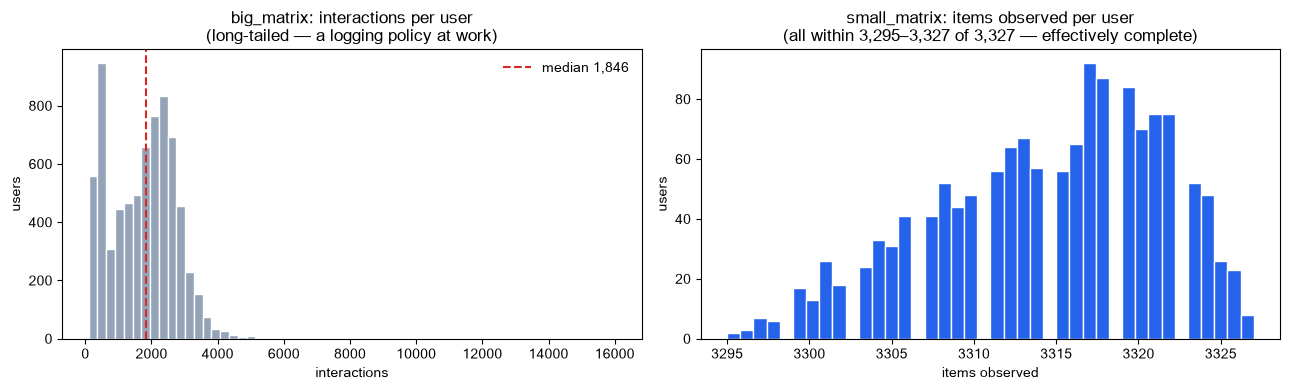

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

per_user_big = big.groupby("user_id").size()
axes[0].hist(per_user_big, bins=60, color="#94a3b8", edgecolor="white")
axes[0].axvline(per_user_big.median(), color="#dc2626", ls="--",
                label=f"median {int(per_user_big.median()):,}")
axes[0].set_title("big_matrix: interactions per user\n(long-tailed — a logging policy at work)")
axes[0].set_xlabel("interactions"); axes[0].set_ylabel("users"); axes[0].legend(frameon=False)

axes[1].hist(per_user, bins=40, color="#2563eb", edgecolor="white")
axes[1].set_title(f"small_matrix: items observed per user\n(all within {per_user.min():,}–{per_user.max():,} of "
                  f"{len(small_items):,} — effectively complete)")
axes[1].set_xlabel("items observed"); axes[1].set_ylabel("users")
fig.tight_layout()
plt.show()

## 5  What the label is: `watch_ratio`

There are no ratings, likes or clicks at interaction level — only `play_duration / video_duration`. Any
binary target has to be a threshold on it, and the choice is a modelling decision, not a given. The KuaiRec
paper and most follow-up work use **`watch_ratio >= 2.0`**.

In [27]:
thresholds = pd.DataFrame([
    {
        "threshold": t,
        "positive_rate_big": float((big["watch_ratio"] >= t).mean()),
        "positive_rate_small": float((small["watch_ratio"] >= t).mean()),
        "median_positives_per_user_small": float(
            small.assign(y=small["watch_ratio"] >= t).groupby("user_id")["y"].sum().median()
        ),
        "users_with_zero_positives": int(
            (small.assign(y=small["watch_ratio"] >= t).groupby("user_id")["y"].sum() == 0).sum()
        ),
    }
    for t in (0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 5.0)
])
display(
    thresholds.style
    .format({"positive_rate_big": "{:.4f}", "positive_rate_small": "{:.4f}",
             "median_positives_per_user_small": "{:.0f}"})
    .hide(axis="index")
    .set_caption("Choosing the positive threshold on watch_ratio")
)

POSITIVE_THRESHOLD = 2.0
small_pos = small.assign(y=small["watch_ratio"] >= POSITIVE_THRESHOLD)
print(f"\nAt the conventional watch_ratio >= {POSITIVE_THRESHOLD}: "
      f"{small_pos['y'].mean():.4f} positive rate, and NO user has zero positives "
      f"(minimum is {int(small_pos.groupby('user_id')['y'].sum().min())} positive items).")
print("Contrast Coat, where 53 of 290 users (18.3%) had no positive in their pool at all.")

threshold,positive_rate_big,positive_rate_small,median_positives_per_user_small,users_with_zero_positives
0.500000,0.6410,0.7273,2500,0
1.000000,0.3382,0.3240,1040,0
1.500000,0.1505,0.1121,315,0
2.000000,0.0747,0.0465,95,0
2.500000,0.0421,0.0245,41,3
3.000000,0.0274,0.0154,22,19
5.000000,0.0092,0.0049,5,137



At the conventional watch_ratio >= 2.0: 0.0465 positive rate, and NO user has zero positives (minimum is 6 positive items).
Contrast Coat, where 53 of 290 users (18.3%) had no positive in their pool at all.


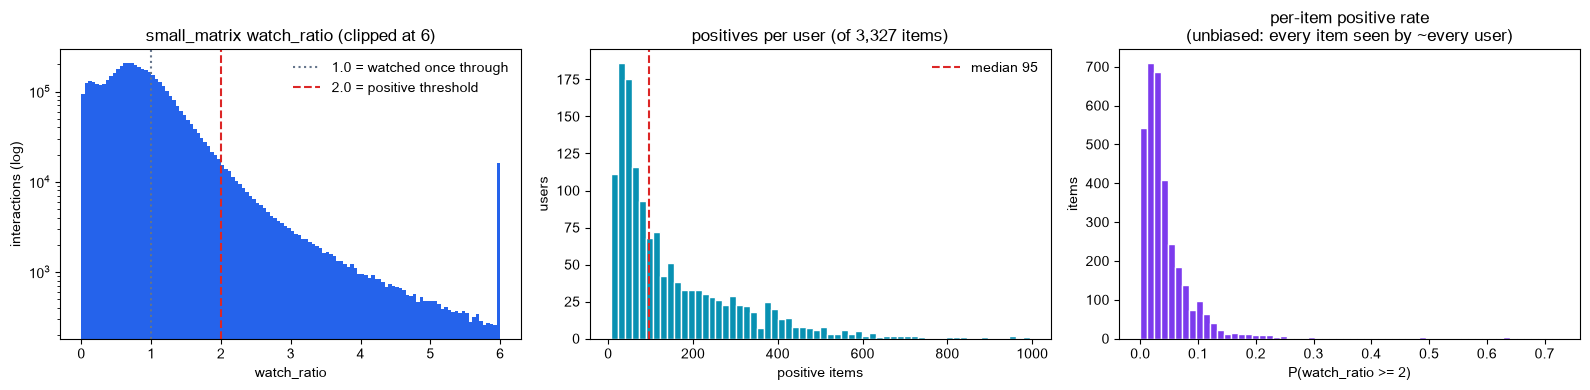

items with zero positives: 51 of 3,327
per-item positive rate spans 0.0000 to 0.7250 — real quality differences, not a degenerate target.


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

clipped = small["watch_ratio"].clip(upper=6)
axes[0].hist(clipped, bins=120, color="#2563eb", edgecolor="none")
axes[0].axvline(1.0, color="#64748b", ls=":", label="1.0 = watched once through")
axes[0].axvline(2.0, color="#dc2626", ls="--", label="2.0 = positive threshold")
axes[0].set_yscale("log")
axes[0].set_title("small_matrix watch_ratio (clipped at 6)")
axes[0].set_xlabel("watch_ratio"); axes[0].set_ylabel("interactions (log)"); axes[0].legend(frameon=False)

user_pos = small_pos.groupby("user_id")["y"].sum()
axes[1].hist(user_pos, bins=60, color="#0891b2", edgecolor="white")
axes[1].axvline(user_pos.median(), color="#dc2626", ls="--", label=f"median {int(user_pos.median())}")
axes[1].set_title(f"positives per user (of {len(small_items):,} items)")
axes[1].set_xlabel("positive items"); axes[1].set_ylabel("users"); axes[1].legend(frameon=False)

item_pos = small_pos.groupby("video_id")["y"].mean()
axes[2].hist(item_pos, bins=60, color="#7c3aed", edgecolor="white")
axes[2].set_title("per-item positive rate\n(unbiased: every item seen by ~every user)")
axes[2].set_xlabel("P(watch_ratio >= 2)"); axes[2].set_ylabel("items")
fig.tight_layout()
plt.show()

print(f"items with zero positives: {(item_pos == 0).sum()} of {len(item_pos):,}")
print(f"per-item positive rate spans {item_pos.min():.4f} to {item_pos.max():.4f} — "
      "real quality differences, not a degenerate target.")

## 6  The MNAR signature

Is the bias actually there, and does it hurt? Two questions, and they have opposite answers — which is the
most consequential finding in this notebook for how the experiment should be framed.

In [29]:
eval_items = sorted(small_items)

exposure_big = big[big["video_id"].isin(small_items)].groupby("video_id").size().reindex(eval_items, fill_value=0)
quality_small = small_pos.groupby("video_id")["y"].mean().reindex(eval_items)
quality_big = (
    big[big["video_id"].isin(small_items)]
    .assign(y=lambda d: d["watch_ratio"] >= POSITIVE_THRESHOLD)
    .groupby("video_id")["y"].mean().reindex(eval_items)
)

from scipy.stats import spearmanr

rho_expo = spearmanr(exposure_big, quality_small).statistic
rho_qual = spearmanr(quality_big, quality_small).statistic

print("Q1. Does how often the logging policy showed an item predict its unbiased quality?")
print(f"    Spearman(exposure in big, P(wr>=2) in small) = {rho_expo:+.4f}")
print("\nQ2. Does item quality measured on biased traffic predict unbiased quality?")
print(f"    Spearman(P(wr>=2) in big, P(wr>=2) in small)  = {rho_qual:+.4f}")
print(f"    level shift: {quality_big.mean():.4f} on biased traffic vs {quality_small.mean():.4f} unbiased "
      f"({quality_big.mean() / quality_small.mean():.2f}x inflation)")
print(f"\n    exposure concentration: the top 10% of items hold "
      f"{exposure_big.sort_values(ascending=False).head(len(eval_items) // 10).sum() / exposure_big.sum():.1%} "
      f"of all exposure")

Q1. Does how often the logging policy showed an item predict its unbiased quality?
    Spearman(exposure in big, P(wr>=2) in small) = -0.0120

Q2. Does item quality measured on biased traffic predict unbiased quality?
    Spearman(P(wr>=2) in big, P(wr>=2) in small)  = +0.9324
    level shift: 0.0698 on biased traffic vs 0.0465 unbiased (1.50x inflation)

    exposure concentration: the top 10% of items hold 19.0% of all exposure


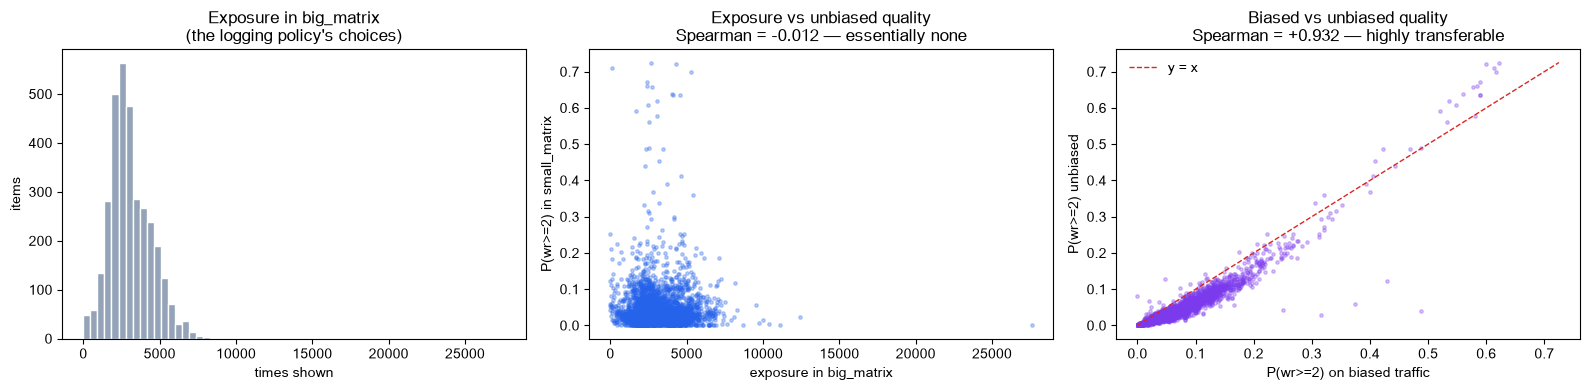

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(exposure_big, bins=60, color="#94a3b8", edgecolor="white")
axes[0].set_title("Exposure in big_matrix\n(the logging policy's choices)")
axes[0].set_xlabel("times shown"); axes[0].set_ylabel("items")

axes[1].scatter(exposure_big, quality_small, s=6, alpha=0.3, color="#2563eb")
axes[1].set_title(f"Exposure vs unbiased quality\nSpearman = {rho_expo:+.3f} — essentially none")
axes[1].set_xlabel("exposure in big_matrix"); axes[1].set_ylabel("P(wr>=2) in small_matrix")

axes[2].scatter(quality_big, quality_small, s=6, alpha=0.3, color="#7c3aed")
lims = [0, float(max(quality_big.max(), quality_small.max()))]
axes[2].plot(lims, lims, color="#dc2626", ls="--", lw=1, label="y = x")
axes[2].set_title(f"Biased vs unbiased quality\nSpearman = {rho_qual:+.3f} — highly transferable")
axes[2].set_xlabel("P(wr>=2) on biased traffic"); axes[2].set_ylabel("P(wr>=2) unbiased")
axes[2].legend(frameon=False)
fig.tight_layout()
plt.show()

**Read these two numbers together — they say different things and both matter.**

*Popularity is not quality here.* Exposure in the logged traffic carries essentially **no** information
about how good an item is under full observation (ρ ≈ −0.01). On Coat, a popularity scorer recovered the
unbiased policy ordering at τ = 0.414 and beat 14 of 16 LLM scorers; that shortcut should not exist on
KuaiRec. The floor should sit near zero, which leaves real room for a semantic scorer to demonstrate
something rather than merely match a counting baseline.

*But item quality itself transfers almost perfectly.* Measured on a **disjoint set of users** under biased
exposure, per-item positive rate ranks items at ρ ≈ +0.93 against the unbiased truth, with a 1.5×
level inflation — almost exactly Coat's 1.48× MNAR inflation. So the bias here is predominantly a
**calibration** shift, not a re-ordering of item quality.

The consequence for the paper is sharp: on this dataset a simulator cannot win by being good at *item
quality*, because a trivial estimator from biased data already nails that. Whatever separates policies has
to come from **personalisation** — matching items to the right users. That is a cleaner test of a user
simulator than Coat offered, and it should be stated as the claim rather than discovered later.

## 7  Headroom: how much room do policies have to differ?

Coat's failure was not primarily its 290 users. It was that each user had 16 labelled items and slates were
5 of them, so every policy's utility landed in 0.190–0.260 with the top three separated by 0.0034 —
far inside the bootstrap noise. The question for KuaiRec is whether the achievable range is wide enough
that policy differences survive resampling.

In [31]:
K_VALUES = (5, 10, 20)
positives_per_user = small_pos.groupby("user_id")["y"].sum()
random_baseline = float(small_pos["y"].mean())

headroom = pd.DataFrame([
    {
        "k": k,
        "random@k": random_baseline,
        "oracle@k": float(np.minimum(positives_per_user, k).mean() / k),
        "users_with_>=k_positives": int((positives_per_user >= k).sum()),
        "coverage": float((positives_per_user >= k).mean()),
    }
    for k in K_VALUES
])
headroom["span"] = headroom["oracle@k"] - headroom["random@k"]
display(headroom.style.format({
    "random@k": "{:.4f}", "oracle@k": "{:.4f}", "span": "{:.4f}", "coverage": "{:.1%}",
}).hide(axis="index").set_caption("Achievable utility range under free retrieval over the 3,327 eval items"))

COAT_SPAN = 0.4848 - 0.1853
kuai_span = float(headroom.loc[headroom["k"] == 5, "span"].iloc[0])
print(f"\nCoat span at k=5:    {COAT_SPAN:.4f}   (random 0.1853 -> oracle 0.4848)")
print(f"KuaiRec span at k=5: {kuai_span:.4f}   ({kuai_span / COAT_SPAN:.2f}x wider)")

k,random@k,oracle@k,users_with_>=k_positives,coverage,span
5,0.0465,1.0000,1411,100.0%,0.9535
10,0.0465,0.9991,1406,99.6%,0.9527
20,0.0465,0.9859,1332,94.4%,0.9394



Coat span at k=5:    0.2995   (random 0.1853 -> oracle 0.4848)
KuaiRec span at k=5: 0.9535   (3.18x wider)


In [32]:
comparison = pd.DataFrame([
    {"quantity": "evaluation users", "Coat": 290, "KuaiRec": len(small_users),
     "note": f"{len(small_users) / 290:.1f}x -> bootstrap CIs ~{np.sqrt(len(small_users) / 290):.1f}x narrower"},
    {"quantity": "labelled items per user", "Coat": 16, "KuaiRec": int(per_user.median()),
     "note": "free retrieval becomes possible; no 16-item pool ceiling"},
    {"quantity": "candidate catalogue", "Coat": 300, "KuaiRec": len(small_items),
     "note": "every candidate carries a real label — no zero-fill"},
    {"quantity": "users with zero positives", "Coat": 53, "KuaiRec": int((positives_per_user == 0).sum()),
     "note": "Coat lost 18.3% of users to a degenerate target"},
    {"quantity": "utility span at k=5", "Coat": round(COAT_SPAN, 4), "KuaiRec": round(kuai_span, 4),
     "note": "the range policies can actually occupy"},
    {"quantity": "popularity shortcut", "Coat": "tau=0.414", "KuaiRec": f"rho={rho_expo:+.3f}",
     "note": "on Coat popularity beat 14/16 LLM scorers; here it should not"},
])
display(comparison.style.hide(axis="index").set_caption("KuaiRec vs Coat on the dimensions that broke Coat"))

quantity,Coat,KuaiRec,note
evaluation users,290,1411,4.9x -> bootstrap CIs ~2.2x narrower
labelled items per user,16,3315,free retrieval becomes possible; no 16-item pool ceiling
candidate catalogue,300,3327,every candidate carries a real label — no zero-fill
users with zero positives,53,0,Coat lost 18.3% of users to a degenerate target
utility span at k=5,0.299500,0.953500,the range policies can actually occupy
popularity shortcut,tau=0.414,rho=-0.012,on Coat popularity beat 14/16 LLM scorers; here it should not


## 8  Text and language coverage

An LLM scorer needs something to read. KuaiRec ships Chinese captions and a Chinese category taxonomy —
nothing in English. This section measures what is actually there, since translation cost scales with it.

In [33]:
eval_captions = captions[captions["video_id"].isin(small_items)].copy()


def usable(series: pd.Series) -> pd.Series:
    return series.notna() & (series.str.strip() != "") & (series != "UNKNOWN")


text_coverage = pd.DataFrame([
    {
        "field": field,
        "eval_items_with_content": int(usable(eval_captions[field]).sum()),
        "coverage": float(usable(eval_captions[field]).mean()),
        "median_chars": float(eval_captions.loc[usable(eval_captions[field]), field].str.len().median()),
    }
    for field in ("caption", "manual_cover_text", "topic_tag",
                  "first_level_category_name", "second_level_category_name",
                  "third_level_category_name")
])
display(text_coverage.style.format({"coverage": "{:.1%}", "median_chars": "{:.0f}",
                                    "eval_items_with_content": "{:,}"})
        .hide(axis="index")
        .set_caption(f"Free-text coverage over the {len(small_items):,} evaluation items"))

n_translate = int(usable(eval_captions["caption"]).sum())
print(f"\nItems needing translation for a prompt-based scorer: ~{n_translate:,}")
print(f"For comparison, the KuaiRand-Pure translation already done in "
      f"`quairank_mnar_experiment/semantic_translation_gpt55/` covered 7,506 items "
      f"({n_translate / 7506:.0%} of that job).")

field,eval_items_with_content,coverage,median_chars
caption,"3,169",95.3%,29
manual_cover_text,"1,472",44.2%,7
topic_tag,"3,327",100.0%,5
first_level_category_name,"3,324",99.9%,2
second_level_category_name,"2,533",76.1%,4
third_level_category_name,"1,321",39.7%,4



Items needing translation for a prompt-based scorer: ~3,169
For comparison, the KuaiRand-Pure translation already done in `quairank_mnar_experiment/semantic_translation_gpt55/` covered 7,506 items (42% of that job).


In [34]:
# What the text actually looks like, and how distinct items are from one another.
sample_cols = ["video_id", "caption", "first_level_category_name",
               "second_level_category_name", "third_level_category_name"]
display(eval_captions[sample_cols].head(8))

dup_captions = eval_captions.loc[usable(eval_captions["caption"]), "caption"]
print(f"\ndistinct captions among the {len(dup_captions):,} eval items with one: {dup_captions.nunique():,}")
print(f"exact-duplicate captions: {len(dup_captions) - dup_captions.nunique():,}")

cat_path = (
    eval_captions["first_level_category_name"].fillna("?") + " > "
    + eval_captions["second_level_category_name"].fillna("?") + " > "
    + eval_captions["third_level_category_name"].fillna("?")
)
print(f"distinct 3-level category paths among eval items: {cat_path.nunique():,}")
print(f"items sharing their full category path with at least one other: "
      f"{int(cat_path.duplicated(keep=False).sum()):,} ({cat_path.duplicated(keep=False).mean():.1%})")
print("\nA category path alone does NOT identify an item — the caption is what makes items distinguishable,")
print("which is the Gate-A question Coat had to answer with synthesised titles.")

,video_id,caption,first_level_category_name,second_level_category_name,third_level_category_name
103,103,用半张饺子皮就能包馄饨简单漂亮，又省事，喜欢赶快动手试试吧。#快手九周年 #爱官方爱热门支持快手传播正能量,美食,美食教程,菜肴
109,109,今天不教你们压弯过几天 #中国摩博会 #ClMA骑士,汽车,玩车,机车族
120,120,哈哈哈跑出一股偷菜贼的感觉,喜剧,UNKNOWN,UNKNOWN
122,122,#搞笑 #搞笑配音,喜剧,搞笑配音,UNKNOWN
128,128,,美食,美食日常,美食分享
130,130,猫猫不仅会开酒，还会用脚弹钢琴#感谢快手我要上热门 @快手创作者服务中心(O40300138),艺术,UNKNOWN,UNKNOWN
131,131,#迷惑行为大赏 #安全第一,喜剧,喜剧段子,UNKNOWN
133,133,你别动，搞得我都烦死了😂,其他,生活泛拍,UNKNOWN



distinct captions among the 3,169 eval items with one: 3,124
exact-duplicate captions: 45
distinct 3-level category paths among eval items: 262
items sharing their full category path with at least one other: 3,241 (97.4%)

A category path alone does NOT identify an item — the caption is what makes items distinguishable,
which is the Gate-A question Coat had to answer with synthesised titles.


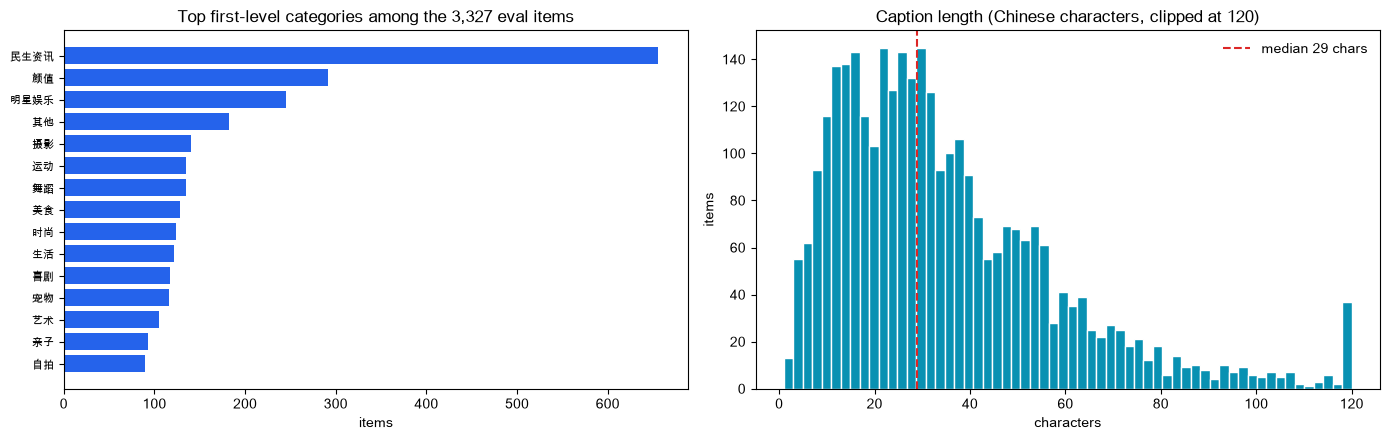

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

top_cats = eval_captions["first_level_category_name"].value_counts().head(15)[::-1]
axes[0].barh(range(len(top_cats)), top_cats.to_numpy(), color="#2563eb")
axes[0].set_yticks(range(len(top_cats)))
axes[0].set_yticklabels(top_cats.index, fontsize=8)
axes[0].set_title("Top first-level categories among the 3,327 eval items")
axes[0].set_xlabel("items")

lengths = eval_captions.loc[usable(eval_captions["caption"]), "caption"].str.len()
axes[1].hist(lengths.clip(upper=120), bins=60, color="#0891b2", edgecolor="white")
axes[1].axvline(lengths.median(), color="#dc2626", ls="--", label=f"median {int(lengths.median())} chars")
axes[1].set_title("Caption length (Chinese characters, clipped at 120)")
axes[1].set_xlabel("characters"); axes[1].set_ylabel("items"); axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

## 9  Data-quality gotchas

Each of these is silent — none raises unless you check for it.

In [36]:
gotchas = []

# 1. Caption CSV newline corruption
physical = sum(1 for _ in (DATA / "kuairec_caption_category.csv").open(encoding="utf-8")) - 1
gotchas.append({
    "issue": "kuairec_caption_category.csv has raw newlines inside unquoted captions",
    "detail": f"{physical:,} physical lines vs {len(captions):,} real records",
    "impact": "pandas C engine raises; the python engine silently returns 4 extra torn rows with wrong ids",
    "handled": "load_caption_category() in §2.1",
})

# 2. NaN dates in small_matrix
nan_dates = int(small["date"].isna().sum())
gotchas.append({
    "issue": "small_matrix.date has nulls",
    "detail": f"{nan_dates:,} rows ({nan_dates / len(small):.1%}); the column is float, not int",
    "impact": "any date-based split or daily-feature join drops or mis-keys these rows",
    "handled": "use `timestamp` (never null) for ordering",
})

# 3. Repeat interactions in big
gotchas.append({
    "issue": "big_matrix repeats (user, video) pairs",
    "detail": f"{len(big) - len(big_pairs):,} repeat rows ({(len(big) - len(big_pairs)) / len(big):.1%})",
    "impact": "a naive groupby-count treats re-watches as separate users' evidence",
    "handled": "decide explicitly: collapse or keep as events",
})

# 4. video_raw_categories coverage gap
missing_vrc = len(small_items - set(video_raw_categories["video_id"]))
gotchas.append({
    "issue": "video_raw_categories_multi.csv does not cover every video",
    "detail": f"{len(big_items - set(video_raw_categories['video_id']))} of {len(big_items):,} videos absent "
              f"({missing_vrc} of them in the eval set)",
    "impact": "an inner join silently drops items from the catalogue",
    "handled": "left-join and treat absence as a category of its own",
})

# 5. item_daily_features grain
gotchas.append({
    "issue": "item_daily_features.csv is per (video, date), not per video",
    "detail": f"{len(item_daily):,} rows over {item_daily['date'].nunique()} dates for "
              f"{item_daily['video_id'].nunique():,} videos",
    "impact": "a direct merge on video_id fans each item out ~32x; daily counts joined post-hoc leak the future",
    "handled": "aggregated in §3 before joining",
})

# 6. feat anonymisation
gotchas.append({
    "issue": "item_categories.feat ids are anonymised",
    "detail": f"{len(all_feats)} ids, no names shipped; {len(FEAT_NAMES)} recovered via the caption table",
    "impact": "prompts built from `feat` alone would show meaningless integers",
    "handled": "FEAT_NAMES lookup in §2.2",
})

# 7. UNKNOWN sentinel
unknown_cols = [c for c in user_features_raw.columns
                if user_features_raw[c].astype(str).eq("UNKNOWN").any()]
gotchas.append({
    "issue": "'UNKNOWN' is used as a string sentinel, not NaN",
    "detail": f"{len(unknown_cols)} columns in user_features_raw contain it; "
              f"also present in captions and categories",
    "impact": "null counts read as zero; 'UNKNOWN' becomes a legitimate-looking category in prompts",
    "handled": "filter explicitly wherever coverage is measured",
})

display(pd.DataFrame(gotchas).style.hide(axis="index"))

issue,detail,impact,handled
kuairec_caption_category.csv has raw newlines inside unquoted captions,"10,732 physical lines vs 10,728 real records",pandas C engine raises; the python engine silently returns 4 extra torn rows with wrong ids,load_caption_category() in §2.1
small_matrix.date has nulls,"181,992 rows (3.9%); the column is float, not int",any date-based split or daily-feature join drops or mis-keys these rows,use `timestamp` (never null) for ordering
"big_matrix repeats (user, video) pairs","2,229,837 repeat rows (17.8%)",a naive groupby-count treats re-watches as separate users' evidence,decide explicitly: collapse or keep as events
video_raw_categories_multi.csv does not cover every video,"45 of 10,728 videos absent (6 of them in the eval set)",an inner join silently drops items from the catalogue,left-join and treat absence as a category of its own
"item_daily_features.csv is per (video, date), not per video","343,341 rows over 63 dates for 10,728 videos",a direct merge on video_id fans each item out ~32x; daily counts joined post-hoc leak the future,aggregated in §3 before joining
item_categories.feat ids are anonymised,"31 ids, no names shipped; 28 recovered via the caption table",prompts built from `feat` alone would show meaningless integers,FEAT_NAMES lookup in §2.2
"'UNKNOWN' is used as a string sentinel, not NaN",12 columns in user_features_raw contain it; also present in captions and categories,null counts read as zero; 'UNKNOWN' becomes a legitimate-looking category in prompts,filter explicitly wherever coverage is measured


In [37]:
# watch_ratio has an extreme upper tail — worth knowing before any mean-based aggregation.
print("watch_ratio upper tail:")
for q in (0.99, 0.999, 0.9999, 1.0):
    print(f"  q{q:<7} big={big['watch_ratio'].quantile(q):9.2f}   small={small['watch_ratio'].quantile(q):9.2f}")
print(f"\nrows with watch_ratio > 10: big {int((big['watch_ratio'] > 10).sum()):,}, "
      f"small {int((small['watch_ratio'] > 10).sum()):,}")
print(f"rows with watch_ratio == 0: big {int((big['watch_ratio'] == 0).sum()):,}, "
      f"small {int((small['watch_ratio'] == 0).sum()):,}")
print("\nA mean watch_ratio is dominated by looping videos. Thresholding (as in §5) is the robust choice;")
print("if a continuous target is ever needed, clip first.")

watch_ratio upper tail:
  q0.99    big=     4.79   small=     3.59
  q0.999   big=    18.03   small=    12.15
  q0.9999  big=    65.43   small=    57.35
  q1.0     big=   573.46   small=   571.52

rows with watch_ratio > 10: big 33,188, small 6,361
rows with watch_ratio == 0: big 240,151, small 30,312

A mean watch_ratio is dominated by looping videos. Thresholding (as in §5) is the robust choice;
if a continuous target is ever needed, clip first.


## 10  Verdict

In [38]:
verdict = pd.DataFrame([
    {"question": "Is the unbiased reference real?",
     "finding": f"small_matrix is {len(small) / (len(small_users) * len(small_items)):.1%} dense over "
                f"{len(small_users):,} x {len(small_items):,}",
     "status": "YES — full observation, not a sample"},
    {"question": "Is train/eval separation clean?",
     "finding": f"{len(overlap)} cells overlap; {len(in_block):,} big rows inside the eval block",
     "status": "YES — leakage-free by construction"},
    {"question": "Is the target non-degenerate?",
     "finding": f"P(wr>=2)={small_pos['y'].mean():.4f}; "
                f"{int((positives_per_user == 0).sum())} users with zero positives; "
                f"{int((item_pos == 0).sum())} items with zero",
     "status": "YES"},
    {"question": "Is there room for policies to differ?",
     "finding": f"utility span at k=5 is {kuai_span:.3f} vs Coat's {COAT_SPAN:.3f}",
     "status": f"YES — {kuai_span / COAT_SPAN:.1f}x Coat"},
    {"question": "Will CIs be narrow enough?",
     "finding": f"{len(small_users):,} users vs Coat's 290 "
                f"(~{np.sqrt(len(small_users) / 290):.1f}x narrower) on a {kuai_span / COAT_SPAN:.1f}x wider span",
     "status": "LIKELY — needs a bootstrap on real policies to confirm"},
    {"question": "Does a popularity shortcut exist?",
     "finding": f"Spearman(exposure, unbiased quality) = {rho_expo:+.3f}",
     "status": "NO — unlike Coat"},
    {"question": "Can a trivial baseline fake the item ordering?",
     "finding": f"Spearman(biased quality, unbiased quality) = {rho_qual:+.3f}",
     "status": "YES — so the claim must be about personalisation"},
    {"question": "Is there text for an LLM scorer?",
     "finding": f"{n_translate:,} of {len(small_items):,} eval items have a caption; all Chinese",
     "status": "YES — translation required"},
])
display(
    verdict.style
    .apply(lambda col: [
        "color:#15803d;font-weight:bold" if str(v).startswith(("YES", "NO", "LIKELY")) else ""
        for v in col], subset=["status"])
    .hide(axis="index")
)

question,finding,status
Is the unbiased reference real?,"small_matrix is 99.6% dense over 1,411 x 3,327","YES — full observation, not a sample"
Is train/eval separation clean?,0 cells overlap; 0 big rows inside the eval block,YES — leakage-free by construction
Is the target non-degenerate?,P(wr>=2)=0.0465; 0 users with zero positives; 51 items with zero,YES
Is there room for policies to differ?,utility span at k=5 is 0.954 vs Coat's 0.299,YES — 3.2x Coat
Will CIs be narrow enough?,"1,411 users vs Coat's 290 (~2.2x narrower) on a 3.2x wider span",LIKELY — needs a bootstrap on real policies to confirm
Does a popularity shortcut exist?,"Spearman(exposure, unbiased quality) = -0.012",NO — unlike Coat
Can a trivial baseline fake the item ordering?,"Spearman(biased quality, unbiased quality) = +0.932",YES — so the claim must be about personalisation
Is there text for an LLM scorer?,"3,169 of 3,327 eval items have a caption; all Chinese",YES — translation required


### What this means

KuaiRec fixes the two things that made Coat uninformative. The evaluation block is **fully observed**, so
the reference ordering carries no exposure-sampling noise at all; and free retrieval over 3,327 fully
labelled candidates gives policies a **3.2× wider** utility range to separate in, on **4.9× more users**.
Train/eval separation is not merely clean but structural — the big matrix contains zero rows inside the
evaluation block, so the overlap-removal step Coat needed does not exist here.

Two findings should shape the claim rather than be discovered later:

**The popularity shortcut is gone.** Exposure in the logged traffic tells you nothing about unbiased quality
(ρ ≈ −0.01). On Coat the popularity scorer beat 14 of 16 LLM scorers and every method's interval spanned it;
that particular embarrassment should not recur.

**But item quality transfers almost perfectly** (ρ ≈ +0.93 from a disjoint user population, with a 1.5×
calibration shift). A simulator therefore cannot distinguish itself by judging *items* well — a trivial
estimator from biased data already does. Whatever separates policies here must come from matching items to
the right *users*. That is the sharper claim, and it is worth stating as the hypothesis rather than
defending after the fact.

Costs to price in before committing: ~3,169 Chinese captions to translate (roughly 42% of the KuaiRand job
already done in `quairank_mnar_experiment/`), and a CF policy roster that must learn evaluation-item factors
from a disjoint user set — a genuinely harder transfer than a random split, and one whose hyperparameters
will not carry over from ml-1m or Coat.

The one thing this notebook cannot settle is whether the CIs actually close. That needs a fitted policy
roster and a user-level bootstrap, exactly as in `notebooks/policy_ranking_agreement_rerank.ipynb` §6 — the
Gate C step.